# Movie-evoked responses

Select **Python (dbh)** and run these **six steps** in order. The supplied data
cover 148 children. See the [setup instructions](../README.md#setup) for installation.

| Step | What it does | Result |
|---|---|---|
| 1 | Choose input paths and whether to use saved results or recompute | Run settings and one log |
| 2 | Check participant IDs, HRV, EEG and intensity ratings | Input summary |
| 3 | Compare SAM ratings and cardiac responses across the three movies | Overall and pairwise tests |
| 4 | Test emotion-minus-neutral IBI and frontal EEG time courses | Significant time clusters |
| 5 | Correlate physiological dynamics with movie intensity | Table S2 |
| 6 | Assemble the subjective, cardiac and time-course panels | Figure S1 |

**Inputs** — paths below are relative to the repository root:

| Data | Location |
|---|---|
| Participant information and SAM ratings | `00_data/participants.csv` |
| IBI and LF/HF time series | `01_preprocessing/outputs/manuscript/ecg/hrv/ecg_ts.npz` |
| EEG band power | `01_preprocessing/outputs/manuscript/eeg/band_power/` |
| Movie-intensity ratings | `00_data/events/Movies_rating_by_RA.csv` |

**Outputs:** `results/SI/Table_S2_intensity_correlations.csv` and
`results/SI/Figure_S1_movie_responses.png`. Detailed tables and plotting inputs
are saved in this folder's `cache/`; each run writes one concise file in `logs/`.
The tables and figure are also displayed below.


## 1. Choose paths and reuse/recompute mode

The defaults select the supplied 148-child data. Relative paths are resolved from
the repository root. When the prompt appears, type **1** or **2** and press Enter:

- **1 — use saved results (default):** read each complete saved step. The supplied
  `cache/` holds the results of the submitted analysis, so this reproduces the
  manuscript output; if any required file is missing or empty, that step is recomputed.
- **2 — recompute and replace:** rerun every analysis step you execute, including
  its saved tables and figure. Use this after changing inputs or analysis settings.

Pressing Enter alone selects 1. The choice applies to steps 3–6 for this run.
Rerunning step 1 lets you choose again and starts a new log; later steps append
to the current log.


In [3]:
from importlib import import_module, reload
from pathlib import Path
import os
import sys

import pandas as pd
from IPython.display import HTML, Image, Markdown, display

override = os.environ.get("ELICITING_PROJECT_ROOT")
candidates = [Path(override).expanduser()] if override else [Path.cwd(), *Path.cwd().parents]
ROOT = next(
    (p.resolve() for p in candidates
     if (p / "02_eliciting_effects/config/eliciting_config.py").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the repository, or set ELICITING_PROJECT_ROOT.")

EFFECTS = ROOT / "02_eliciting_effects"
INFO_FILE = ROOT / "00_data/participants.csv"
ECG_FILE = ROOT / "01_preprocessing/outputs/manuscript/ecg/hrv/ecg_ts.npz"
EEG_DIR = ROOT / "01_preprocessing/outputs/manuscript/eeg/band_power"
RATINGS_FILE = ROOT / "00_data/events/Movies_rating_by_RA.csv"
OUTPUT_ROOT = Path(os.environ.get("ELICITING_OUTPUT_ROOT", str(EFFECTS)))

sys.path.insert(0, str(ROOT))
RunLog = reload(import_module("common.run_log")).RunLog
cache_policy = reload(import_module("common.cache_policy"))
settings = reload(import_module("02_eliciting_effects.config.eliciting_config"))
inputs = reload(import_module("02_eliciting_effects.analysis.inputs"))
compare_movies = reload(import_module("02_eliciting_effects.analysis.analyze_movie_responses")).run_analysis
test_timecourses = reload(import_module("02_eliciting_effects.analysis.analyze_eeg_ibi_timecourses")).run_analysis
correlate_intensity = reload(import_module("02_eliciting_effects.analysis.analyze_intensity_correlations")).run_analysis
draw_figure = reload(import_module("02_eliciting_effects.plotting.plot_figure_s1")).plot_figure_s1

PATHS = settings.make_paths(
    root=ROOT, participants=INFO_FILE, ecg_file=ECG_FILE, eeg_dir=EEG_DIR,
    ratings=RATINGS_FILE, output_root=OUTPUT_ROOT,
)
RESULT_DIR = PATHS.results
FIGURE_DIR = PATHS.figures
TABLE_DIR = PATHS.tables
LOG = RunLog(PATHS.output / "logs", ROOT, title="Eliciting effects", announce=False)
display(HTML('<style id="dbh-notebook-style">' +
             (ROOT / "common/notebook_style.css").read_text(encoding="utf-8") + "</style>"))

RECOMPUTE = cache_policy.choose_recompute()
UPDATED_STEPS = set()
LOG.write("Run mode: recompute and replace" if RECOMPUTE else "Run mode: use complete cached results")
for heading, items in (("Inputs (read only)", [("Participants", PATHS.participants), ("HRV", PATHS.ecg),
                                               ("EEG power", PATHS.eeg_dir), ("Movie ratings", PATHS.ratings)]),
                       ("Outputs", [("Analysis cache", RESULT_DIR), ("Tables and figures", TABLE_DIR)])):
    print(heading)
    LOG.write(heading)
    for label, location in items:
        print(f"  {label:<20}{LOG.display(location)}")
        LOG.write(f"  {label:<20}{LOG.display(location)}")
print("Run log:", LOG.display(LOG.path))


1 = use complete saved results; compute missing or outdated steps (default)
2 = recompute and replace saved results and figures
Choose 2 after changing the input data or analysis settings.


Type 1 or 2, then press Enter (Enter alone = 1):  2


Inputs (read only)
  Participants        00_data/participants.csv
  HRV                 01_preprocessing/outputs/manuscript/ecg/hrv/ecg_ts.npz
  EEG power           01_preprocessing/outputs/manuscript/eeg/band_power
  Movie ratings       00_data/events/Movies_rating_by_RA.csv
Outputs
  Analysis cache      02_eliciting_effects/cache
  Tables and figures  results/SI
Run log: 02_eliciting_effects/logs/20261030_223046.log


## 2. Check and inspect the inputs

Match the participant IDs across HRV and EEG files, and check the movie labels,
sampling grids, electrode labels and intensity ratings. Missing or invalid inputs
stop the analysis.

The table below shows the data that were found. `participants`, `cardiac`,
`eeg_files` and `movie_intensity` remain available for inspection.

In [5]:
with LOG.step("Check inputs"):
    LOG.command([sys.executable, ROOT / "check_setup.py", "--python-only", "--quiet"])

    participants, cardiac = inputs.load_cohort(PATHS)
    eeg_files = inputs.get_eeg_files(PATHS, cardiac["ids"])
    inputs.check_eeg_inputs(eeg_files, settings.REGIONS)
    movie_intensity = inputs.load_intensity(PATHS)

    input_summary = pd.DataFrame([
        {"Input": "Participants", "Available": len(participants)},
        {"Input": "IBI (subjects × movies × samples)", "Available": str(cardiac["ibi"].shape)},
        {"Input": "LF/HF (subjects × movies × samples)", "Available": str(cardiac["lf"].shape)},
        {"Input": "EEG power files", "Available": len(eeg_files)},
        {"Input": "Movie intensity", "Available": "2 movies × 176 seconds"},
    ])
    display(input_summary.style.hide(axis="index"))
    LOG.write(f"Inputs passed: {len(participants)} participants, {len(eeg_files)} EEG files, two intensity tracks")


Python 3.12.7: /opt/anaconda3/envs/dbh/bin/python
[OK] numpy 2.2.6; scipy 1.16.3; pandas 2.3.3; matplotlib 3.10.8; sklearn 1.8.0; statsmodels 0.14.6; h5py 3.16.0; joblib 1.4.2; numba 0.61.2; llvmlite 0.44.0; tqdm 4.66.5; mne 1.11.0; neurokit2 0.2.13; IPython 9.17.1; ipykernel 6.28.0; jupyterlab 4.2.5; nbformat 5.10.4; tkinter available
Validated 148 EEG files: channel labels, frequencies, times and band shapes.


Input,Available
Participants,148
IBI (subjects × movies × samples),"(148, 3, 704)"
LF/HF (subjects × movies × samples),"(148, 3, 176)"
EEG power files,148
Movie intensity,2 movies × 176 seconds


## 3. Compare the three movie conditions

Compare fearful, happy and neutral movies for SAM arousal, SAM valence, IBI,
LF-HRV and HF-HRV. Cardiac measures use each child's temporal mean; LF/HF power
is natural-log transformed before averaging.

Run the repeated-measures F test, followed by three paired t tests per measure
with Holm correction. The overall and pairwise results are displayed below;
condition means and all test tables are saved in `cache/`.

In [7]:
with LOG.step("Movie condition comparisons"):
    response_files = [RESULT_DIR / name for name in [
        "eliciting_effects_omnibus.csv", "eliciting_effects_posthoc.csv",
        "eliciting_effects_means.csv", "movie_responses_manifest.json",
    ]]
    if cache_policy.use_cached_results(
        response_files, recompute=RECOMPUTE, label="Movie comparisons", log=LOG,
    ):
        omnibus_results = pd.read_csv(RESULT_DIR / "eliciting_effects_omnibus.csv")
    else:
        LOG.write("Parameters: repeated-measures F; paired t tests; Holm correction within each measure")
        omnibus_results = compare_movies(PATHS, print_tables=False)
        UPDATED_STEPS.add("movie comparisons")
    pairwise_results = pd.read_csv(RESULT_DIR / "eliciting_effects_posthoc.csv")
    condition_means = pd.read_csv(RESULT_DIR / "eliciting_effects_means.csv")

    display(Markdown("**Overall condition effects**"))
    display(omnibus_results.style.hide(axis="index").format({"F_mv": "{:.2f}", "p_mv": "{:.3g}"}))
    display(Markdown("**Pairwise comparisons**"))
    display(pairwise_results[["measure", "a", "b", "mean_diff", "t", "p_corr", "dz"]]
            .style.hide(axis="index").format({
                "mean_diff": "{:.3f}", "t": "{:.2f}", "p_corr": "{:.3g}", "dz": "{:.2f}",
            }))
    LOG.write(f"Results: {len(omnibus_results)} overall tests and {len(pairwise_results)} paired tests in {RESULT_DIR}")


Movie comparisons: recomputing and replacing saved results.
Saved response tables to: 02_eliciting_effects/cache


**Overall condition effects**

measure,n,F_mv,df1_mv,df2_mv,p_mv
IBI,148,51.30,2,146,1.34e-17
HF,148,7.46,2,146,0.00082
LF,148,6.47,2,146,0.00204
Arousal,148,48.02,2,146,9.42e-17
Valence,148,65.94,2,146,3.95e-21


**Pairwise comparisons**

measure,a,b,mean_diff,t,p_corr,dz
IBI,Fearful,Happy,-22.122,-8.87,6.72e-15,-0.73
IBI,Fearful,Neutral,-8.440,-2.90,0.00425,-0.24
IBI,Happy,Neutral,13.682,6.62,1.27e-09,0.54
HF,Fearful,Happy,-0.132,-3.87,0.000486,-0.32
HF,Fearful,Neutral,-0.081,-2.49,0.028,-0.20
HF,Happy,Neutral,0.051,1.73,0.0866,0.14
LF,Fearful,Happy,-0.051,-1.17,0.245,-0.10
LF,Fearful,Neutral,-0.152,-3.57,0.00147,-0.29
LF,Happy,Neutral,-0.101,-2.27,0.0489,-0.19
Arousal,Fearful,Happy,0.338,1.35,0.18,0.11


## 4. Find significant changes over time

Subtract each child's neutral temporal mean from the fearful and happy time
series. Test IBI at 4 Hz and natural-log EEG power averaged across 18 frontal
electrodes at 1 Hz.

Each test uses **10,000 sign-flip permutations**, seed 0, two-sided p < .05 and
clusters lasting at least 5 s. Missing differences become zero for the cluster
test. EEG uses the first 176 stored samples, with interpolation of missing
regional bins, displayed on the 0–175 s sample-index axis.

This is the longest step; progress appears for each test. Significant clusters
are displayed below. `temporal_clusters` and the saved CSV include every candidate
cluster. Correction is within each test, with no additional correction across tests.

In [9]:
with LOG.step("Temporal cluster tests"):
    cluster_file = RESULT_DIR / "neuro_dynamics_clusters.csv"
    if cache_policy.use_cached_results(
        [cluster_file, RESULT_DIR / "timecourses_manifest.json"],
        recompute=RECOMPUTE, label="Time-course tests", log=LOG,
    ):
        temporal_clusters = pd.read_csv(cluster_file, keep_default_na=False)
    else:
        LOG.write(
            f"Parameters: {settings.N_PERM} sign flips per test; seed {settings.SEED}; "
            f"alpha {settings.CL_ALPHA}; minimum cluster {settings.MIN_LEN} s; neutral-mean baseline"
        )
        temporal_clusters = test_timecourses(PATHS, print_tables=False)
        UPDATED_STEPS.add("time-course tests")
    significant_clusters = temporal_clusters.loc[temporal_clusters["p"] < settings.CL_ALPHA]

    print(f"Significant clusters: {len(significant_clusters)} / {len(temporal_clusters)} candidates")
    if significant_clusters.empty:
        print("No significant temporal clusters.")
    else:
        display(significant_clusters.style.hide(axis="index").format({
            "t_start_s": "{:.2f}", "t_end_s": "{:.2f}", "tsum": "{:.2f}", "p": "{:.4f}",
        }))
    LOG.write(f"Clusters: {len(temporal_clusters)} candidates, {len(significant_clusters)} significant")
    LOG.write(f"Results: {cluster_file}")


Time-course tests: recomputing and replacing saved results.
47 clusters -> 02_eliciting_effects/cache/neuro_dynamics_clusters.csv
Significant clusters: 47 / 47 candidates


signal,band,emotion,t_start_s,t_end_s,tsum,p
IBI,,fear,35.25,42.00,120.96,0.0013
IBI,,fear,45.50,50.50,-79.25,0.0064
IBI,,fear,54.75,60.75,-71.25,0.0082
IBI,,fear,69.75,76.00,-85.96,0.0050
IBI,,fear,124.75,132.75,121.30,0.0013
IBI,,fear,142.50,149.50,-139.95,0.0006
IBI,,fear,151.50,156.75,-101.97,0.0024
IBI,,fear,161.00,171.50,-303.27,0.0001
EEG,delta,fear,9.00,14.00,-18.02,0.0005
EEG,delta,fear,31.00,39.00,-46.59,0.0001


## 5. Relate physiological dynamics to movie intensity

Correlate each movie's intensity with group-mean dynamics relative to neutral:
IBI, LF-HRV, HF-HRV, and four EEG bands in frontal, central and posterior regions
(**15 correlations per movie**).

Use intensity seconds 0–175, min–max scaled without smoothing, and reduce IBI
to 1 Hz. Apply BH-FDR to the 15 Pearson p values within each movie. Also report
p values from **10,000 phase-randomised surrogates**, without FDR adjustment.

Display Table S2 and save it to `results/SI/`. `correlation_results` contains the
30 detailed tests, including the paired time-point counts. Figure inputs are
saved to `cache/` for the next step.

In [11]:
with LOG.step("Movie intensity correlations"):
    table_s2_file = TABLE_DIR / "Table_S2_intensity_correlations.csv"
    correlation_file = RESULT_DIR / "intensity_correlations_long.csv"
    if cache_policy.use_cached_results(
        [correlation_file, table_s2_file, RESULT_DIR / "figure_s1_inputs.npz",
         RESULT_DIR / "intensity_manifest.json"],
        recompute=RECOMPUTE, label="Intensity correlations", log=LOG,
    ):
        correlation_results = pd.read_csv(correlation_file)
    else:
        LOG.write(
            f"Parameters: 15 Pearson correlations per movie; BH-FDR within movie; "
            f"{settings.N_SURR} phase surrogates; seed {settings.SEED}"
        )
        correlation_results = correlate_intensity(PATHS, print_tables=False)
        UPDATED_STEPS.add("intensity correlations")
    table_s2 = pd.read_csv(table_s2_file, dtype=str, keep_default_na=False)

    display(Markdown("**Table S2. Correlations with movie intensity**"))
    display(table_s2.style.hide(axis="index"))
    LOG.write(f"Results: {len(correlation_results)} correlations; {table_s2_file}")


Intensity correlations: recomputing and replacing saved results.
Saved Table S2 and figure inputs to: 02_eliciting_effects/cache


**Table S2. Correlations with movie intensity**

Measure,Fearful r,Fearful pFDR,Fearful p surrogate,Happy r,Happy pFDR,Happy p surrogate
IBI,-0.14,0.088,0.650,0.17,0.054,0.316
LF-HRV,0.05,0.574,0.635,-0.09,0.247,0.553
HF-HRV,-0.30,<.001,0.199,0.10,0.240,0.499
Frontal delta,-0.24,0.003,0.081,-0.21,0.013,0.116
Frontal theta,-0.12,0.128,0.391,-0.11,0.204,0.358
Frontal alpha,0.22,0.007,0.095,0.33,<.001,0.020
Frontal beta,0.49,<.001,0.002,-0.06,0.445,0.700
Central delta,-0.32,<.001,0.024,-0.24,0.003,0.093
Central theta,-0.14,0.100,0.435,-0.02,0.755,0.879
Central alpha,0.36,<.001,0.034,0.43,<.001,0.004


## 6. Draw or display Figure S1

Combine the saved results into three panels: **(a)** SAM changes, **(b)** cardiac
condition means and **(c)** intensity tracks with IBI/frontal EEG dynamics.

Mode 1 displays the saved figure when it is up to date. If an earlier analysis
step was recomputed, the plotting inputs changed, or the figure is missing, it
is redrawn. Mode 2 redraws and replaces the figure.

The figure is displayed below and saved to `results/SI/`. For figure-only use,
run steps 1 and 6; the analysis tables must already exist when redrawing.


Figure S1: recomputing and replacing saved results.
Saved: results/SI/Figure_S1_movie_responses.png


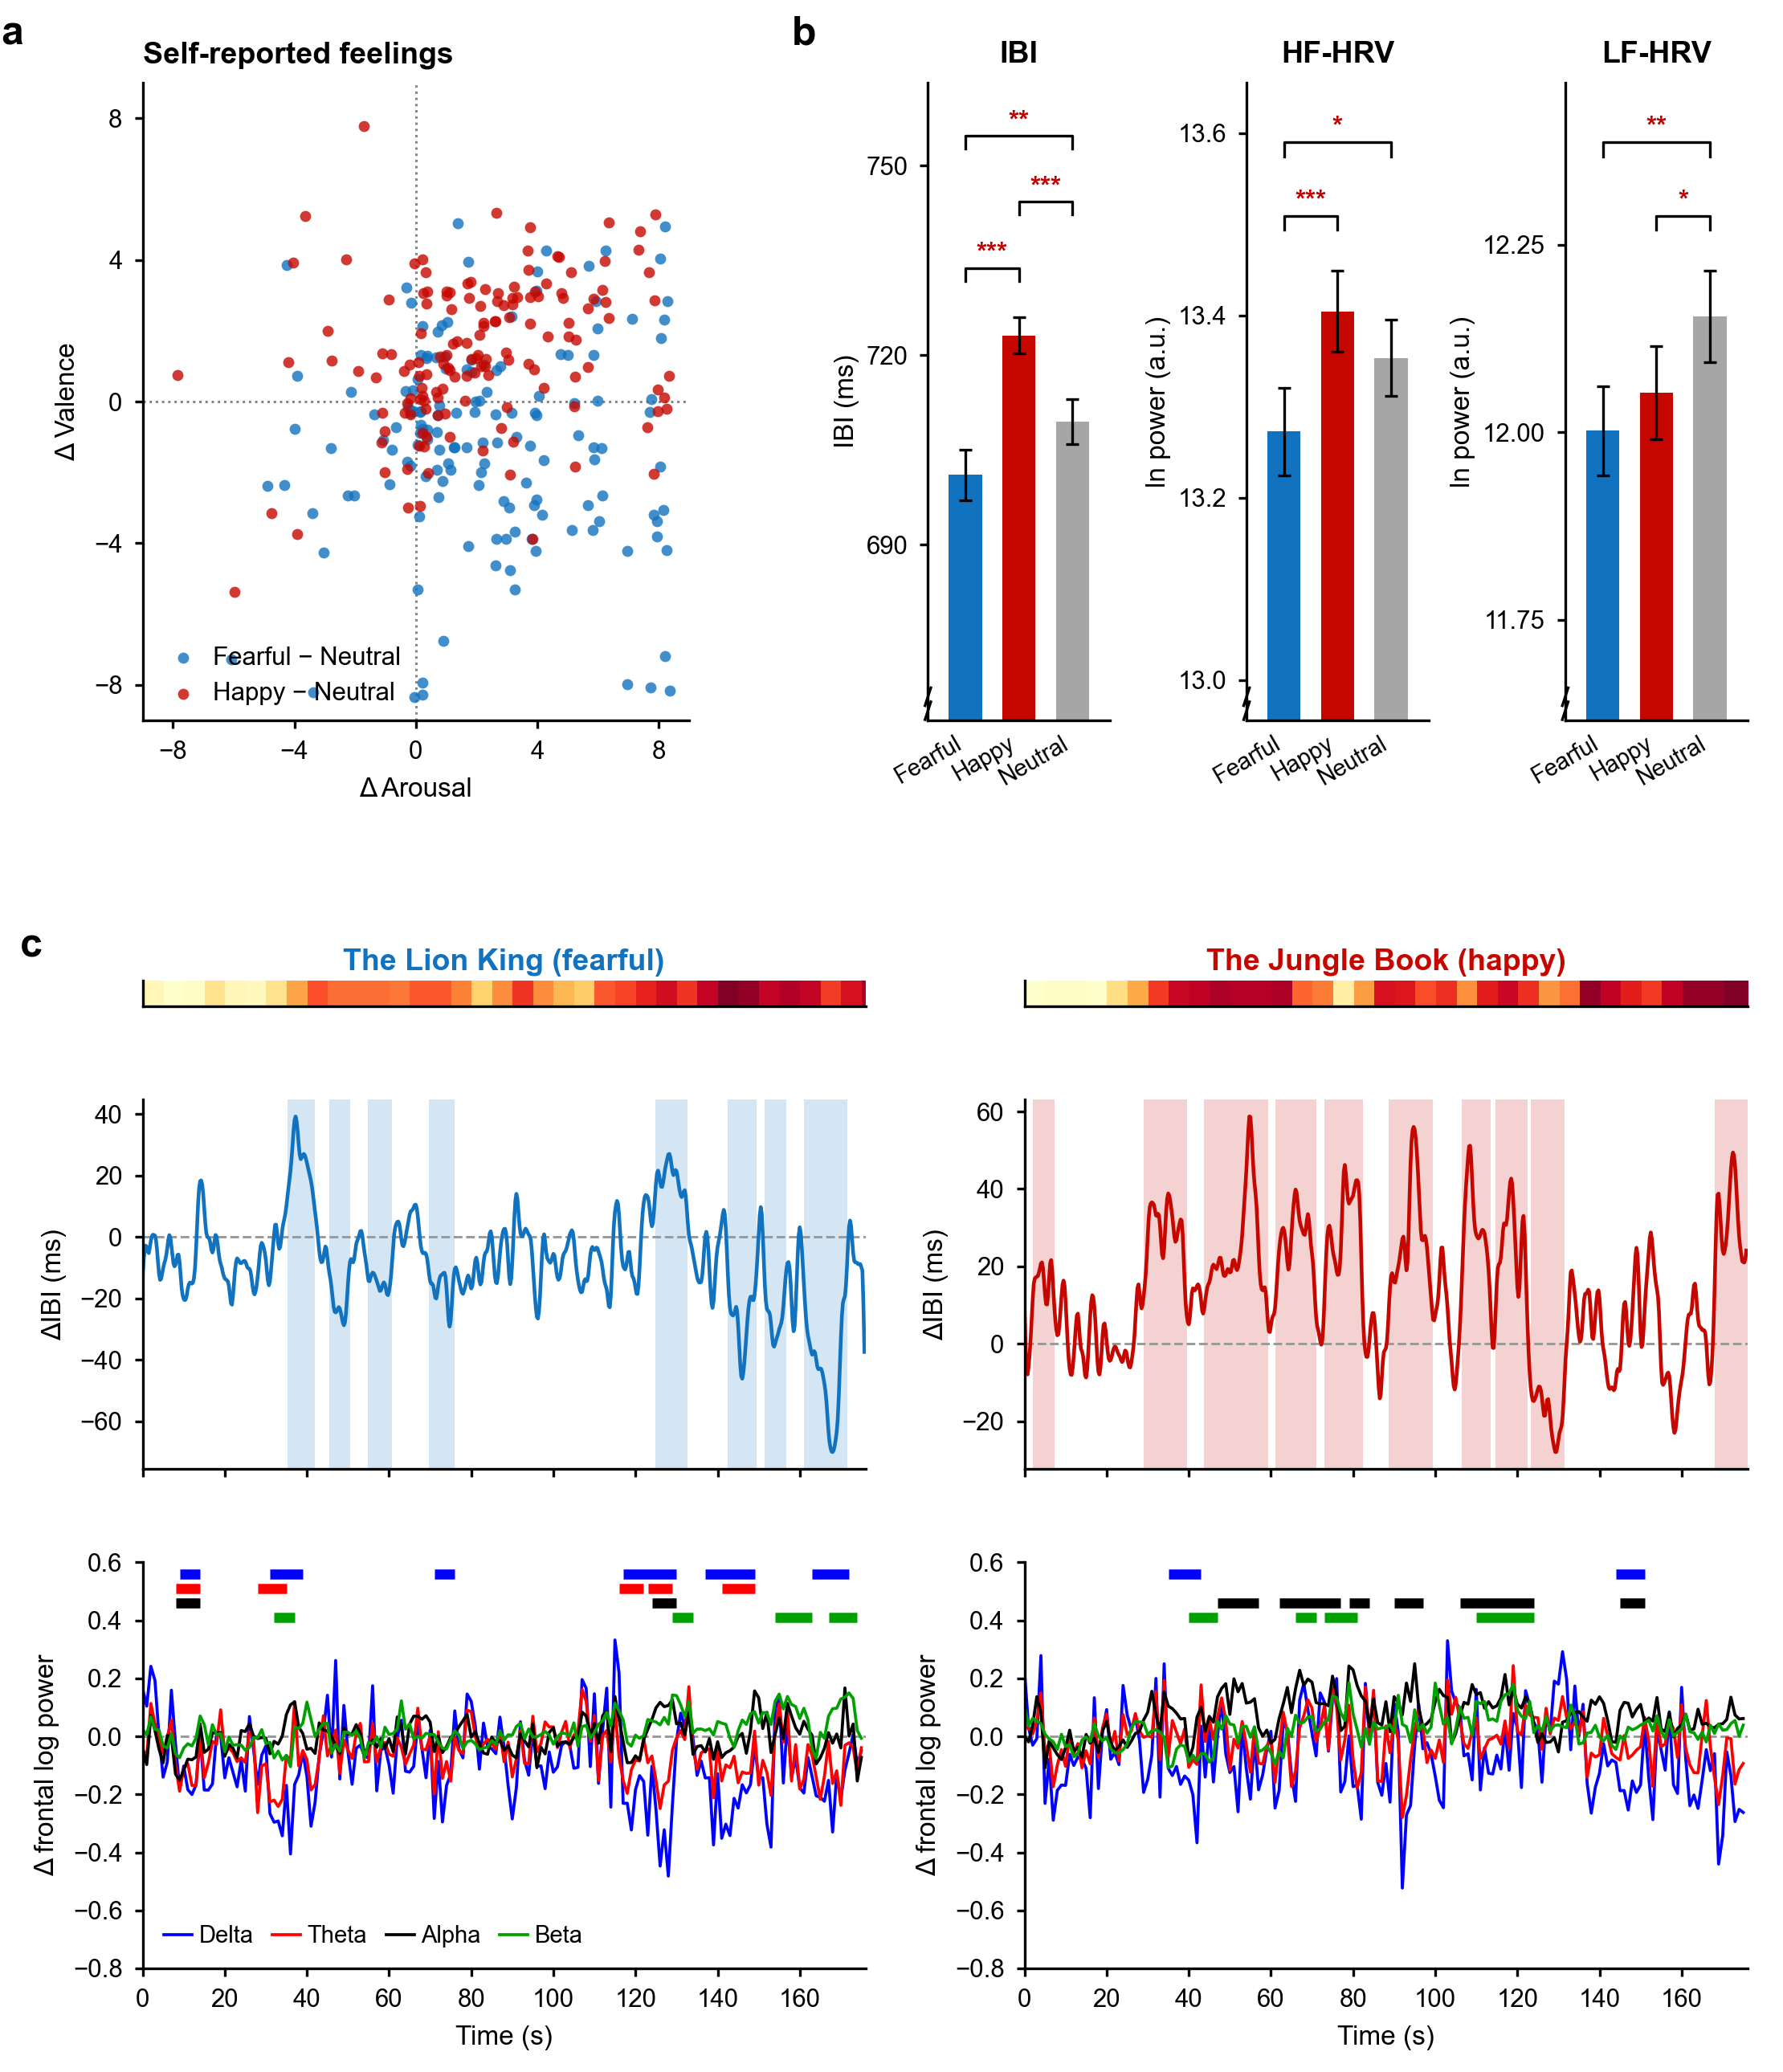

Table S2: results/SI/Table_S2_intensity_correlations.csv
Figure S1: results/SI/Figure_S1_movie_responses.png
Run log: 02_eliciting_effects/logs/20261030_223046.log


In [13]:
with LOG.step("Figure S1"):
    figure_file = FIGURE_DIR / "Figure_S1_movie_responses.png"
    figure_sources = [
        RESULT_DIR / "figure_s1_inputs.npz",
        RESULT_DIR / "eliciting_effects_posthoc.csv",
        RESULT_DIR / "neuro_dynamics_clusters.csv",
        EFFECTS / "plotting/plot_figure_s1.py",
        EFFECTS / "config/eliciting_config.py",
    ]
    redraw = RECOMPUTE or bool(UPDATED_STEPS) or cache_policy.figure_needs_update(figure_file, figure_sources)
    if not cache_policy.use_cached_results(
        [figure_file], recompute=redraw, label="Figure S1", log=LOG,
    ):
        figure_file = draw_figure(RESULT_DIR, FIGURE_DIR)
        UPDATED_STEPS.clear()
    display(Image(filename=str(figure_file), width=1000))
    LOG.write(f"Figure: {figure_file}")

print("Table S2:", LOG.display(TABLE_DIR / "Table_S2_intensity_correlations.csv"))
print("Figure S1:", LOG.display(figure_file))
print("Run log:", LOG.display(LOG.path))


## Further manuscript analyses

The analysis order is **eliciting → correlation → HEP → dBHI**. After this
notebook, open the following entries in order:

| Analysis | What it examines | Outputs |
|---|---|---|
| [Correlation](../03_correlation/run_correlation.ipynb) | EEG–IBI covariation across movie conditions and age groups | Figure 2; Figure S2 |
| [HEP](../04_HEP/run_hep.ipynb) | Heartbeat-locked EEG responses and their age effects | Figure 3; Table S3 |
| [dBHI](../05_dBHI/run_dbhi.ipynb) | Directional brain–heart coupling, age prediction and intensity contrasts | Figures 4–5; Figures S3–S7; Tables S4–S6 |

These are separate analyses of the supplied cohort data; each notebook describes
its own inputs and steps.
